# 05 - The Arena

All methods, all error structures, scored on the two axes that matter: **coverage**
(does the 90% interval contain the truth 90% of the time?) and **efficiency** (at equal
coverage, tighter is better).

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.artifacts import save_fig, save_json

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NOMINAL = 0.90
SEED = 42

In [2]:
from src.datasets.synthetic import STRUCTURES, make_synthetic
from src.evaluation.comparison import run_arena
from src.evaluation.coverage import coverage
from src.intervals.normal import NormalInterval
from src.intervals.quantile_regression import QuantileRegressor
from src.intervals.gbm_quantile import GBMQuantileInterval
from src.intervals.bootstrap import BootstrapInterval
from src.intervals.conformal import SplitConformal, AdaptiveConformal
from sklearn.linear_model import LinearRegression

factories = {
    "normal": lambda: NormalInterval(coverage=NOMINAL),
    "quantile_regression": lambda: QuantileRegressor(quantiles=(0.05, 0.95), n_iter=1500),
    "gbm_quantile": lambda: GBMQuantileInterval(quantiles=(0.05, 0.95), n_estimators=150),
    "bootstrap": lambda: BootstrapInterval(base_estimator=LinearRegression(), n_bootstrap=40, coverage=NOMINAL),
    "split_conformal": lambda: SplitConformal(coverage=NOMINAL),
    "adaptive_conformal": lambda: AdaptiveConformal(coverage=NOMINAL),
}
arena = run_arena(factories, STRUCTURES, n_samples=5000, seed=SEED, nominal=NOMINAL)
arena

,structure,method,coverage,nominal,mean_width
0,homoscedastic,normal,0.884000,0.9,6.397740
1,homoscedastic,quantile_regression,0.938667,0.9,8.543804
2,homoscedastic,gbm_quantile,0.902667,0.9,6.806842
3,homoscedastic,bootstrap,0.039333,0.9,0.177701
4,homoscedastic,split_conformal,0.907333,0.9,6.881258
5,homoscedastic,adaptive_conformal,0.918667,0.9,7.037703
6,heteroscedastic,normal,0.872000,0.9,15.016545
7,heteroscedastic,quantile_regression,0.937333,0.9,15.074191
8,heteroscedastic,gbm_quantile,0.904000,0.9,13.766541
9,heteroscedastic,bootstrap,0.046000,0.9,0.351988


## The coverage scoreboard

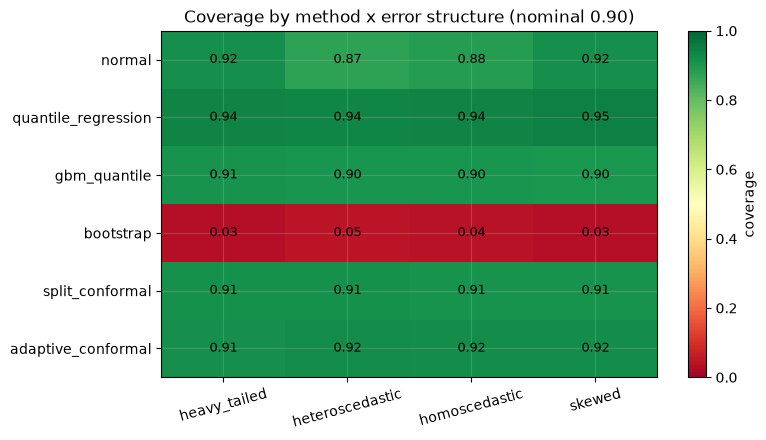

In [3]:
pivot = arena.pivot(index="method", columns="structure", values="coverage").loc[list(factories)]
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(pivot.values, vmin=0.0, vmax=1.0, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns, rotation=15)
ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="coverage")
ax.set_title("Coverage by method x error structure (nominal 0.90)")
save_fig(fig, "05_coverage_heatmap")
plt.show()

## Efficiency: coverage vs width (bottom-right of the nominal line is the goal)

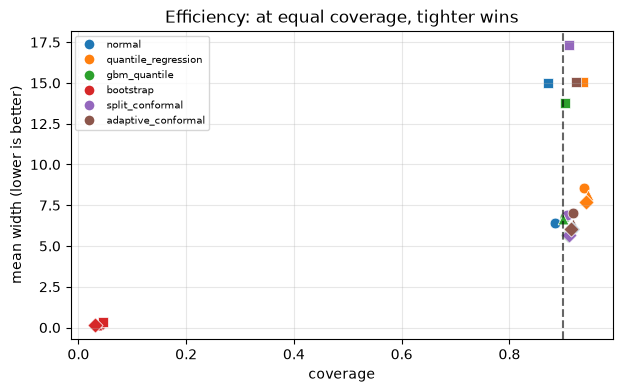

In [4]:
from matplotlib.lines import Line2D

colors = dict(zip(factories, plt.cm.tab10.colors))
markers = {"homoscedastic": "o", "heteroscedastic": "s", "skewed": "^", "heavy_tailed": "D"}
fig, ax = plt.subplots()
for _, r in arena.iterrows():
    ax.scatter(r["coverage"], r["mean_width"], marker=markers[r["structure"]],
               color=colors[r["method"]], s=60, edgecolor="white", linewidth=0.5)
ax.axvline(NOMINAL, color="black", ls="--", alpha=0.6)
ax.set_xlabel("coverage"); ax.set_ylabel("mean width (lower is better)")
ax.set_title("Efficiency: at equal coverage, tighter wins")
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=colors[m], label=m, markersize=8)
           for m in factories]
ax.legend(handles=handles, fontsize=7, loc="upper left")
save_fig(fig, "05_coverage_vs_width")
plt.show()

## Coverage is stable across repeats (the qualitative result is robust)

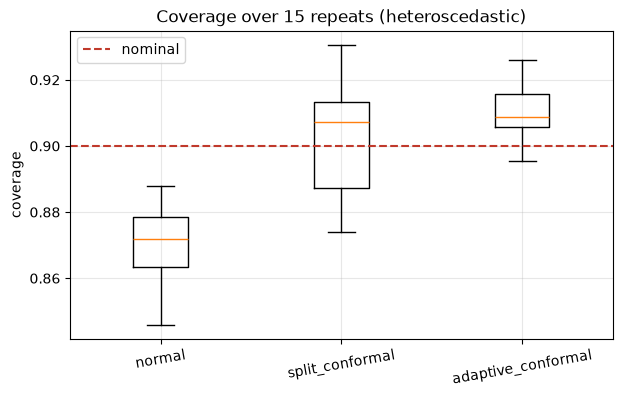

In [5]:
rep_rows = []
for seed in range(100, 115):
    d = make_synthetic("heteroscedastic", 5000, seed)
    xt, yt, xe, ye = d.x[:3500], d.y[:3500], d.x[3500:], d.y[3500:]
    models = {"normal": NormalInterval(coverage=NOMINAL),
              "split_conformal": SplitConformal(coverage=NOMINAL),
              "adaptive_conformal": AdaptiveConformal(coverage=NOMINAL)}
    for name, m in models.items():
        m.fit(xt, yt)
        lo, hi = m.predict_interval(xe)
        rep_rows.append({"seed": seed, "method": name, "coverage": float(coverage(ye, lo, hi))})
rep = pd.DataFrame(rep_rows)

order = ["normal", "split_conformal", "adaptive_conformal"]
fig, ax = plt.subplots()
ax.boxplot([rep[rep.method == m]["coverage"].to_numpy() for m in order])
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=10)
ax.axhline(NOMINAL, color="#C0392B", ls="--", label="nominal"); ax.legend()
ax.set_ylabel("coverage"); ax.set_title("Coverage over 15 repeats (heteroscedastic)")
save_fig(fig, "05_repeats_boxplot")
plt.show()

In [6]:
summary = rep.groupby("method")["coverage"].agg(["mean", "std", "min", "max"]).reset_index()
save_json("05_arena", {
    "nominal_coverage": NOMINAL,
    "arena": arena.to_dict(orient="records"),
    "repeats": rep.to_dict(orient="records"),
    "repeats_summary": summary.to_dict(orient="records"),
})
summary

,method,mean,std,min,max
0,adaptive_conformal,0.910444,0.009356,0.895333,0.926000
1,normal,0.870667,0.012076,0.846000,0.888000
2,split_conformal,0.902044,0.017718,0.874000,0.930667


**Verdict:** the normal interval covers only under its assumptions; quantile methods and
conformal cover broadly; conformal carries a guarantee the others lack; and adaptive
conformal is the best combination of coverage and tightness. The bootstrap, by design,
captures estimate uncertainty rather than predictive uncertainty and collapses here.